In [ ]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from tqdm import tqdm

# Project folders, relative to this notebook (which lives in notebooks/)
PROJECT_ROOT = Path("..")
DATA_DIR = PROJECT_ROOT / "data" / "catsanddogs"
MODELS_DIR = PROJECT_ROOT / "models"
IMAGES_DIR = PROJECT_ROOT / "images"
BEST_MODEL_PATH = MODELS_DIR / "best_model.pt"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch {torch.__version__} | device: {device}")

In [2]:
# Data loading
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ImageFolder takes each label from the folder name and loads every image as RGB,
# including the few grayscale and CMYK ones
image_datasets = {
    split: datasets.ImageFolder(DATA_DIR / split)
    for split in ["train", "validation", "test"]
}

class_names = image_datasets["train"].classes
print(f"Classes: {image_datasets['train'].class_to_idx}")
for split, dataset in image_datasets.items():
    counts = np.bincount(dataset.targets)
    print(f"{split}: {len(dataset)} images | " + ", ".join(
        f"{name}: {count}" for name, count in zip(class_names, counts)
    ))

Classes: {'Cat': 0, 'Dog': 1}
train: 19793 images | Cat: 9910, Dog: 9883
validation: 2474 images | Cat: 1239, Dog: 1235
test: 2474 images | Cat: 1238, Dog: 1236


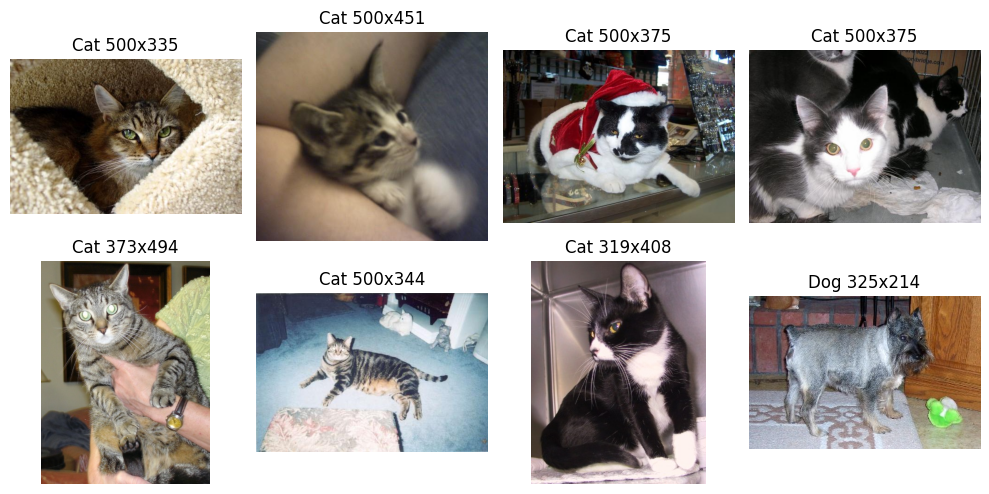

In [3]:
# Look at some raw training images before any preparation
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, index in zip(axes.flat, random.sample(range(len(image_datasets["train"])), 8)):
    image, label = image_datasets["train"][index]
    ax.imshow(image)
    ax.set_title(f"{class_names[label]} {image.size[0]}x{image.size[1]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
# Data preparation
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 4

# Pretrained torchvision models expect images normalized with these ImageNet statistics
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Training images get random augmentation; validation and test stay deterministic
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

image_datasets["train"].transform = train_transform
image_datasets["validation"].transform = eval_transform
image_datasets["test"].transform = eval_transform

loaders = {
    split: DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=split == "train",
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    for split, dataset in image_datasets.items()
}

for split, loader in loaders.items():
    print(f"{split}: {len(loader)} batches of up to {BATCH_SIZE}")

train: 619 batches of up to 32
validation: 78 batches of up to 32
test: 78 batches of up to 32


Batch: torch.Size([32, 3, 224, 224]) | labels: torch.Size([32]) | pixel range: -2.12 to 2.64


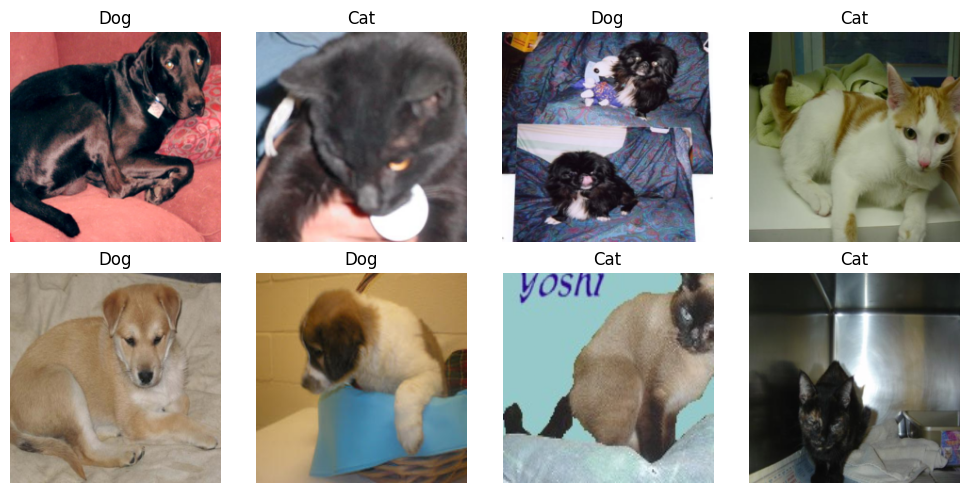

In [5]:
# Check the pipeline: batch shape, value range, and a look at augmented training images
images, labels = next(iter(loaders["train"]))
print(f"Batch: {images.shape} | labels: {labels.shape} | "
      f"pixel range: {images.min():.2f} to {images.max():.2f}")

# Undo the normalization so the images display with their real colours
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, image, label in zip(axes.flat, images, labels):
    ax.imshow((image * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(class_names[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [7]:
# Build the model: EfficientNet-B0 pretrained on ImageNet
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)

# Freeze the pretrained layers so only the new final layer learns at first
for param in model.features.parameters():
    param.requires_grad = False

# Replace the 1,000-class ImageNet output with a 2-class Cat/Dog output
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(class_names))

model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model.classifier)
print(f"Total parameters: {total_params:,} | trainable: {trainable_params:,}")

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)
Total parameters: 4,010,110 | trainable: 2,562


In [ ]:
# Compile: loss function, optimizer and training helpers
import time

criterion = nn.CrossEntropyLoss()

# Only the parameters that aren't frozen (the new Cat/Dog layer) are optimized for now
optimizer = optim.AdamW((p for p in model.parameters() if p.requires_grad), lr=1e-3)

# Mixed precision: the GPU does most of the maths in 16-bit, roughly doubling speed
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

best_val_acc = 0.0
history = []


def run_epoch(loader, optimizer=None):
    """One pass over the data. Trains if an optimizer is given, otherwise just evaluates."""
    training = optimizer is not None
    model.train(training)
    total_loss = correct = count = 0
    with torch.set_grad_enabled(training):
        for images, labels in tqdm(loader, desc="train" if training else "validate", leave=False):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device.type, enabled=use_amp):
                outputs = model(images)
                loss = criterion(outputs, labels)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            count += labels.size(0)
    return total_loss / count, correct / count


def fit(optimizer, epochs, phase):
    """Train for some epochs, checking validation accuracy and saving the best model."""
    global best_val_acc
    for epoch in range(1, epochs + 1):
        start = time.time()
        train_loss, train_acc = run_epoch(loaders["train"], optimizer)
        val_loss, val_acc = run_epoch(loaders["validation"])
        history.append({"phase": phase, "train_loss": train_loss, "train_acc": train_acc,
                        "val_loss": val_loss, "val_acc": val_acc})
        saved = val_acc > best_val_acc
        if saved:
            best_val_acc = val_acc
            torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"[{phase}] epoch {epoch}/{epochs} | "
              f"train loss {train_loss:.4f} acc {train_acc:.2%} | "
              f"val loss {val_loss:.4f} acc {val_acc:.2%} | "
              f"{time.time() - start:.0f}s" + (" | saved best" if saved else ""))


print(f"Loss: {criterion} | optimizer: AdamW lr=1e-3 | mixed precision: {use_amp}")

In [ ]:
# Training phase 1: only the new Cat/Dog layer learns
fit(optimizer, epochs=3, phase="head only")

In [ ]:
# Training phase 2: unfreeze the whole model and fine-tune it gently
for param in model.parameters():
    param.requires_grad = True

# A 10x lower learning rate so the pretrained knowledge is adjusted, not overwritten
optimizer = optim.AdamW(model.parameters(), lr=1e-4)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

fit(optimizer, epochs=5, phase="fine-tune")

# Keep the version that scored best on the validation set
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
print(f"Loaded best model from {BEST_MODEL_PATH} | validation accuracy: {best_val_acc:.2%}")

In [ ]:
# Plot training and validation loss and accuracy for every epoch
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

SERIES = {"train": ("Training", "#2a78d6"), "val": ("Validation", "#eb6834")}
INK, INK_SECONDARY, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"

epochs = list(range(1, len(history) + 1))
fine_tune_start = sum(h["phase"] == "head only" for h in history) + 0.5

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), facecolor=SURFACE)
for ax, metric, title in zip(axes, ["loss", "acc"],
                             ["Loss (lower is better)", "Accuracy (higher is better)"]):
    ax.set_facecolor(SURFACE)
    finals = {}
    for split, (name, color) in SERIES.items():
        values = [h[f"{split}_{metric}"] for h in history]
        ax.plot(epochs, values, color=color, linewidth=2, marker="o", markersize=6,
                markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
        finals[split] = values[-1]

    # Label each line's final value, nudging the higher label up and the lower one down
    higher = max(finals, key=finals.get)
    for split, value in finals.items():
        text = f"{value:.2%}" if metric == "acc" else f"{value:.3f}"
        ax.annotate(f"{SERIES[split][0]} {text}", (epochs[-1], value),
                    xytext=(10, 7 if split == higher else -7), textcoords="offset points",
                    va="center", color=INK_SECONDARY, fontsize=9)

    # Dashed line where phase 2 (unfreezing the whole model) begins, labelled in an empty
    # band at the top of the chart so the label never sits on the data
    ax.margins(y=0.15)
    ax.axvline(fine_tune_start, color=AXIS, linestyle="--", linewidth=1, zorder=1)
    ax.annotate("fine-tuning starts →", (fine_tune_start, 1), xycoords=("data", "axes fraction"),
                xytext=(-5, -5), textcoords="offset points", ha="right", va="top",
                color=MUTED, fontsize=9)

    ax.set_title(title, loc="left", color=INK, fontsize=12, pad=10)
    ax.set_xlabel("Epoch", color=MUTED)
    ax.set_xlim(0.6, epochs[-1] + 2.2)  # room on the right for the value labels
    ax.set_xticks(epochs)
    if metric == "acc":
        ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)

legend_handles = [Line2D([], [], color=color, linewidth=2, marker="o", markersize=6,
                         markeredgecolor=SURFACE, label=name) for name, color in SERIES.values()]
fig.legend(handles=legend_handles, loc="upper center", ncol=2, frameon=False,
           labelcolor=INK_SECONDARY, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

In [ ]:
# Sample predictions on new images the model has never seen
SAMPLE_IMAGES = [IMAGES_DIR / "great pyrenees.webp", IMAGES_DIR / "toletolemeimei.jpg"]

# Load the best saved model, so this cell works without retraining (needs cells 1, 2, 4 and 6)
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
model.eval()

fig, axes = plt.subplots(1, len(SAMPLE_IMAGES), figsize=(5 * len(SAMPLE_IMAGES), 5))
for ax, path in zip(axes, SAMPLE_IMAGES):
    image = Image.open(path).convert("RGB")
    batch = eval_transform(image).unsqueeze(0).to(device)  # same preparation as validation images

    with torch.no_grad():
        probabilities = torch.softmax(model(batch), dim=1)[0].cpu()

    predicted = class_names[probabilities.argmax()]
    print(f"{path.name}: {predicted} | " + ", ".join(
        f"{name} {p:.2%}" for name, p in zip(class_names, probabilities)
    ))

    ax.imshow(image)
    ax.set_title(f"{predicted} ({probabilities.max():.1%} confident)\n{path.name}", fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Final evaluation on the test set: 2,474 images never used for training or choosing the model
from matplotlib.colors import LinearSegmentedColormap

model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
model.eval()

test_preds, test_labels = [], []
with torch.no_grad():
    for images, labels in tqdm(loaders["test"], desc="test"):
        with torch.autocast(device.type, enabled=device.type == "cuda"):
            outputs = model(images.to(device, non_blocking=True))
        test_preds.append(outputs.argmax(1).cpu())
        test_labels.append(labels)
test_preds = torch.cat(test_preds).numpy()
test_labels = torch.cat(test_labels).numpy()

correct = (test_preds == test_labels).sum()
print(f"Test accuracy: {correct / len(test_labels):.2%} ({correct} of {len(test_labels)} correct)\n")
print(classification_report(test_labels, test_preds, target_names=class_names, digits=4))

# Confusion matrix: rows are the real animal, columns are what the model said
matrix = confusion_matrix(test_labels, test_preds)
for i, actual in enumerate(class_names):
    for j, predicted in enumerate(class_names):
        if i != j:
            print(f"{actual}s wrongly predicted as {predicted}: {matrix[i, j]}")

blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#2a78d6", "#0d366b"])
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(
    ax=ax, cmap=blues, colorbar=False, values_format="d")
ax.set_title("Test set: actual vs predicted", loc="left", fontsize=12, pad=10)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
# Show every test image the model got wrong, with how confident it was (needs cell 12 first)
wrong = np.flatnonzero(test_preds != test_labels)
print(f"{len(wrong)} misclassified test images")

COLUMNS = 6
rows = -(-len(wrong) // COLUMNS)  # round up
fig, axes = plt.subplots(rows, COLUMNS, figsize=(COLUMNS * 2.6, rows * 2.9), squeeze=False)
for ax in axes.flat:
    ax.axis("off")

for ax, index in zip(axes.flat, wrong):
    path, actual = image_datasets["test"].samples[index]
    predicted = test_preds[index]
    image = Image.open(path).convert("RGB")
    with torch.no_grad():
        confidence = torch.softmax(model(eval_transform(image).unsqueeze(0).to(device)), dim=1)[0, predicted]

    ax.imshow(image)
    ax.set_title(f"{Path(path).name}\nis {class_names[actual]}, said {class_names[predicted]} "
                 f"({confidence:.0%})", fontsize=8)
plt.tight_layout()
plt.show()